# Complexity-07 — C# — Complexité de Kolmogorov bornée : résolution de séquences numériques à mémoire limitée

**Navigation** : [<< Complexity-06c — Classical at heart](Complexity-06c-ClassicalAtHeart-Python.ipynb) | [Index de la série](README.md) | [Complexity-07b — Le tour des grands nombres →](Complexity-07b-LeTourDesGrandsNombres-Python.ipynb)

**Positionnement.** Distillation de *Bounded Kolmogorov Complexity Based on Cognitive Models* (Strannegård, Nizamani, Sjöberg et Engström, AGI 2013). Le PDF est archivé dans la bibliographie privée du projet ; il n'est jamais recopié ici. La **méthode** du papier (un langage de termes, une métrique de longueur, un calcul borné par une mémoire de travail) est réimplémentée from scratch en Python, et la batterie d'items est de construction maison — les items du test IST cité par le papier restent sous droits.

**L'idée en une phrase.** La complexité de Kolmogorov K(x) — la longueur du plus court programme qui produit x — est incomputable ; les versions computables (compression, Kt de Levin) ignorent la dimension *cognitive* : elles ne disent rien de ce qu'un agent à mémoire limitée peut *vraiment* trouver. Le mouvement du papier : restreindre les calculs à un modèle cognitif borné, puis chercher le plus court terme qui décrit la séquence **dans ce modèle borné**.

**Ce que ce notebook fait de vérifiable :**

1. un solveur complet pour l'espace fini effectivement énuméré (numérales ≤ 99, regards ≤ 3 et longueur bornée), par longueur croissante ;
2. **E1** — balayage de la borne de mémoire B : la prédiction du modèle cognitif est que le score croît (au sens large) puis plateaute avec B — mesuré, pas supposé ;
3. **E2** — paires de séquences appariées dont la structure exige un calcul qui dépasse B : le basculement de réponse doit arriver au seuil prédit par la métrique de longueur ;
4. **E3** — confrontation honnête à deux baselines classiques (interpolation polynomiale, différences finies), verdict par classe d'item.

**Pourquoi ce notebook est falsifiable et pas une démonstration.** Chaque expérience E1-E3 porte une prédiction qui peut échouer : une courbe score(B) non monotone réfuterait la revendication de monotonicité du modèle sur notre batterie ; un basculement E2 qui n'arrive pas au seuil prédit réfuterait la métrique de longueur. Les verdicts sont écrits dans les sorties, y compris négatifs.

**Jumeau C#.** L’énumérateur, la métrique et les prédicats bornés sont natifs, avec entiers de précision arbitraire `BigInteger`. Les budgets, items et expériences sont ceux du Python versionné, source primaire du port ; le papier reste rapporté par ce Python et n’a pas été relu pour ce travail.


## 1. Le problème : pourquoi K ne suffit pas

Une séquence numérique d'un test de type QI est un objet éminemment ambigu. La séquence `1, 2` se continue par 1 (répétition `1,2,1,2`), par 2 (miroir `1,2,2,1`), par 3 (incréments `1,2,3`), par 4 (doublements `1,2,4,8`)… Le « bon » continuant dépend du **sujet** qui regarde — d'où l'idée du papier : modéliser le sujet.

La chaîne de raisonnement :

- K(x) = longueur du plus court programme produisant x : incomputable (problème de l'arrêt), donc inutilisable comme boussole directe ;
- les versions computables (Levin Kt, compression) mesurent une complexité *absolue*, indépendante de l'observateur ;
- un humain résout ces items avec ~7 items en mémoire de travail (Miller) — les patterns qu'il peut trouver sont exactement ceux dont le **calcul tient dans cette fenêtre** ;
- donc : définir K **relativement à un système de réécriture borné**, où la borne modélise la mémoire de travail, et chercher le plus court terme dans ce système borné.

Le papier rapporte que son solveur (Haskell) score 28/38 aux items numériques du test IST — contre 9 pour Mathematica, 9 pour Maple, 12 pour WolframAlpha — et surtout : **passer la mémoire de 8 à 7 items fait baisser le score, passer de 8 à 9 ne le change pas**. C'est cette sensibilité à la borne que E1 réplique sur batterie indépendante.

**Notre batterie n'est pas l'IST** : construite maison, dans l'esprit des items (arithmétiques, géométriques, récurrents, entrelacés, polynomiaux). Toute comparaison chiffrée au 28/38 du papier serait hors de portée — nous comparons le solveur à lui-même à travers la borne B, et à des baselines sur la même batterie.

## 2. Le langage des termes

Les termes décrivent des séquences :

- **numérales** : `0, 1, 2, …` (jusqu'à 99 ici) ;
- **la position** : `n` (index du terme courant, avec décalage possible du point de départ) ;
- **regard en arrière** : `f(n−c)` — la valeur de la séquence c positions plus tôt (c ≤ 3) ;
- **opérations binaires** : `t1 + t2`, `t1 − t2`, `t1 · t2`, `t1 ÷ t2` (division entière, diviseur à un chiffre).

La **longueur d'un terme** (métrique du papier, Def. 3) :

| Terme | Longueur |
|---|---|
| numérale c | nombre de chiffres de c, **zéros traînants ignorés** (`\|10\| = 1`, `\|250\| = 2`) |
| `n` | 1 |
| `f(n−c)` | 1 |
| `t1 ⋆ t2` | `\|t1\| + \|t2\| + 1` |

Un terme **décrit** la séquence `a0 … a(l−1)` si, en notant b le plus grand regard en arrière du terme : `b < l/2` (les cas de base restent minoritaires — règle du papier) et `t(i) = a_i` pour tout `i ≥ b`. Le terme **prédit** alors `t(l)`.

Exemple du papier : `f(n−2)·f(n−1)` décrit `2, 2, 4, 8, 32` et prédit `256`.

Deux extensions du papier sont incluses dans le solveur : les **descriptions modulo m** (sous-séquences entrelacées — ex. `1, 2, 1, 3, 1, 4, 1, 5`) et les **décalages d'index** (le départ de `n` varie — ex. `1, 4, 9, 16, 25` se décrit par `n·n` si `n` démarre à 1).

In [1]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Numerics;
using System.Text;
using System.Diagnostics;
using System.Globalization;
using Microsoft.DotNet.Interactive.Formatting;

// Les coordonnées du SVG restent invariantes entre soumissions.
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
// Les arbres décrivent la grammaire finie : constante, position, regard et opération.
abstract record Terme;
record Num(BigInteger Valeur) : Terme;
record Pos() : Terme;
record Look(int Retour) : Terme;
record Op(string Sym, Terme Gauche, Terme Droite) : Terme;
int LongueurNombre(BigInteger x)
{
    if (x < 0)
        return LongueurNombre(-x) + 1;
    // Les zéros finaux ne comptent pas dans cette métrique de description.
    string s = x.ToString().TrimEnd('0');
    return Math.Max(1, s.Length);
}

// Chaque opérateur ajoute une unité au coût de ses deux sous-termes.
int Longueur(Terme t) => t switch
{
    Num v => LongueurNombre(v.Valeur),
    Pos => 1,
    Look => 1,
    Op o => Longueur(o.Gauche) + Longueur(o.Droite) + 1,
    _ => throw new ArgumentException("Terme inconnu")};
string Affiche(Terme t) => t switch
{
    Num v => v.Valeur.ToString(),
    Pos => "n",
    Look l => $"f(n-{l.Retour})",
    Op o => $"({Affiche(o.Gauche)} {(o.Sym == "*" ? "." : o.Sym == "//" ? ":" : o.Sym)} {Affiche(o.Droite)})",
    _ => throw new ArgumentException("Terme inconnu")};
if (LongueurNombre(10) != 1 || LongueurNombre(250) != 2 || Longueur(new Op("*", new Look(2), new Look(1))) != 3 || Longueur(new Op("*", new Num(67), new Num(89))) != 5)
    throw new Exception("Métrique incorrecte");
Console.WriteLine("Métrique vérifiée : |f(n-2).f(n-1)|=3, |67.89|=5");
var troisieme = new Op("+", new Op("*", new Look(1), new Num(10)), new Num(1));
Console.WriteLine($"|f(n-1).10+1|={Longueur(troisieme)}");
var cube = new Op("*", new Op("*", new Pos(), new Pos()), new Pos());
if (Longueur(cube) != 5)
    throw new Exception("Longueur du cube incorrecte");
Console.WriteLine($"|n.n.n|={Longueur(cube)} (cube, dans le budget L=5)");


Métrique vérifiée : |f(n-2).f(n-1)|=3, |67.89|=5


|f(n-1).10+1|=5


|n.n.n|=5 (cube, dans le budget L=5)


### Lecture du résultat — la métrique de longueur se calibre sur trois exemples

La sortie valide la métrique du papier (Def. 3) : `|f(n-2).f(n-1)| = 3` (deux regards en arrière et une opération), `|67.89| = 5` et `|f(n-1).10+1| = 5` — le zéro traînant de 10 ne compte pas, d'où un terme long (5) avec des opérandes simples et un terme court (3) avec des opérateurs. La longueur mesure le terme, pas la valeur calculée.

### Exercice 1 — Regard admissible

Écrire `LookbackMax(longueur)` : pour une séquence de longueur positive, renvoyer le plus grand entier $b$ tel que $2b < longueur$. Tester les longueurs paires et impaires ; le stub renvoie `null` tant qu'il est ouvert.

In [2]:
int? LookbackMax(int longueur)
{
    // TODO : plus grand entier b vérifiant 2b < longueur.
    return null;
}

var testPremier = LookbackMax(5);
var testAutre = LookbackMax(8);
if (testPremier is null && testAutre is null)
    Console.WriteLine("Exercice 1 à compléter");
else
    foreach (int l in new[]
    {
        1,
        2,
        5,
        6,
        8,
        17,
        100
    }

    )
    {
        var got = LookbackMax(l);
        if (got is null || got.Value != (l - 1) / 2)
            throw new Exception($"Regard admissible incorrect pour longueur {l}");
        Console.WriteLine($"longueur={l}, regard={got}");
    }


Exercice 1 à compléter


## 3. Le calcul borné : le modèle de mémoire de travail

C'est le cœur cognitif du papier. Un terme peut être court et pourtant **incomputable pour un agent borné** : le papier cite `67 · 89` — longueur 5, mais aucune de ses réductions ne tient dans une fenêtre de 8 items, parce que le système de réécriture du papier calcule via des **tables arithmétiques 10×10** (opérandes à un chiffre). Un produit à grands opérandes doit d'abord être **décomposé par distributivité**, et les termes intermédiaires décomposés doivent tenir dans la fenêtre.

**Notre opérationnalisation (déclarée).** Le papier utilise un vrai TRS avec tables ; nous le modélisons par une **arithmétique décomposée récursive sous budget** :

- une opération sur numérales à **un chiffre** est un **accès table** — coût `|a| + 1 + |b| ≤ B` ;
- les gestes élémentaires qu'un humain fait sans charger la mémoire — **×10** (appendre un zéro, gratuit au sens de la métrique puisque les zéros traînants ne comptent pas) et **±1 sur unité** — sont à coût réduit ;
- sinon, le plus grand opérande est décomposé (`x = 10·h + u`), et le **terme décomposé** — par exemple `a·h·10 + a·u` pour le produit — doit tenir dans la fenêtre **B** avant que la récursion continue sur ses sous-calculs ;
- toute valeur intermédiaire de la chaîne doit satisfaire le budget.

Ces prédicats sont un **estimateur de faisabilité** dans un modèle simplifié : ils ne constituent pas une suite d’étapes d’un TRS arithmétique correct et ne reproduisent pas toutes les règles du papier. E2 teste la cohérence interne de ce modèle et du solveur qui emploie les mêmes prédicats ; il ne valide pas indépendamment sa fidélité cognitive.

In [3]:
// Ces prédicats estiment une faisabilité sous budget ; ce n'est pas un TRS arithmétique.
bool Mult(BigInteger a, BigInteger b, int B)
{
    if (a < 0 || b < 0)
        return Mult(BigInteger.Abs(a), BigInteger.Abs(b), B);
    // Ordonner les opérandes permet de décomposer le plus grand en dizaines et unités.
    var big = BigInteger.Max(a, b);
    var small = BigInteger.Min(a, b);
    if (small == 0 || small == 1)
        return true;
    if (small == 10)
        return LongueurNombre(big) <= B;
    if (LongueurNombre(small) == 1 && LongueurNombre(big) == 1)
        return 3 <= B;
    // h et u représentent respectivement le préfixe décimal et le dernier chiffre.
    var h = big / 10;
    var u = big % 10;
    // Le coût décrit l’expression décomposée avant de vérifier ses sous-calculs.
    int cost = LongueurNombre(small) + 1 + LongueurNombre(h) + 1 + LongueurNombre(small) + 1 + LongueurNombre(u);
    return cost <= B && Mult(small * h, 10, B) && Mult(small, u, B);
}

// Les signes renvoient à la soustraction pour garder un traitement positif commun.
bool Addition(BigInteger a, BigInteger b, int B)
{
    if (a < 0 && b < 0)
        return Addition(-a, -b, B) && LongueurNombre(a + b) + 1 <= B;
    if (b < 0)
        return Soustraction(a, -b, B);
    if (a < 0)
        return Soustraction(b, -a, B);
    if (LongueurNombre(a) == 1 && LongueurNombre(b) == 1)
        return 3 <= B;
    var big = BigInteger.Max(a, b);
    var small = BigInteger.Min(a, b);
    if (small == 0 || small == 1)
        return LongueurNombre(big) + 2 <= B;
    var h = big / 10;
    var u = big % 10;
    int cost = LongueurNombre(h) + 1 + LongueurNombre(small) + 1 + LongueurNombre(u) + 1;
    return cost <= B && Addition(h, small, B) && Addition(u, 0, B);
}

bool Soustraction(BigInteger a, BigInteger b, int B)
{
    if (b < 0)
        return Addition(a, -b, B);
    if (a < 0)
        return Addition(-a, b, B) && LongueurNombre(a - b) + 1 <= B;
    if (LongueurNombre(a) == 1 && LongueurNombre(b) == 1)
        return 3 <= B;
    if (b == 0)
        return true;
    var big = BigInteger.Max(a, b);
    var small = BigInteger.Min(a, b);
    if (small == 0 || small == 1)
        return LongueurNombre(big) + 2 <= B;
    var h = big / 10;
    var u = big % 10;
    int cost = LongueurNombre(h) + 1 + LongueurNombre(small) + 1 + LongueurNombre(u) + 1;
    return cost <= B && Soustraction(h, small, B) && Soustraction(u, 0, B);
}

// La division bornée refuse zéro et limite ici le diviseur à un chiffre.
bool Division(BigInteger a, BigInteger b, int B)
{
    if (b == 0)
        return false;
    if (a < 0 || b < 0)
        return Division(BigInteger.Abs(a), BigInteger.Abs(b), B);
    if (LongueurNombre(b) > 1)
        return false;
    if (LongueurNombre(a) == 1)
        return 3 <= B;
    var h = a / 10;
    var u = a % 10;
    int cost = LongueurNombre(h) + 1 + 1 + 1 + LongueurNombre(u);
    return cost <= B && Division(h, b, B) && Division(u, b, B);
}

bool Borne(string op, BigInteger a, BigInteger b, int B) => op switch
{
    "+" => Addition(a, b, B),
    "-" => Soustraction(a, b, B),
    "*" => Mult(a, b, B),
    "//" => Division(a, b, B),
    _ => false
};
// La faisabilité est contrôlée séparément avant d’appliquer l’opération entière.
BigInteger Applique(string op, BigInteger a, BigInteger b) => op switch
{
    "+" => a + b,
    "-" => a - b,
    "*" => a * b,
    "//" => a / b,
    _ => throw new ArgumentException("Opération inconnue")};
Console.WriteLine($"8×32 B8={Mult(8, 32, 8)} ; 67×89 B8={Mult(67, 89, 8)}, B12={Mult(67, 89, 12)} ; 1111×10 B8={Mult(1111, 10, 8)} ; 48×3 B6={Mult(48, 3, 6)}, B7={Mult(48, 3, 7)}");


8×32 B8=True ; 67×89 B8=False, B12=True ; 1111×10 B8=True ; 48×3 B6=False, B7=True


### Lecture du résultat — prédicats bornés et taille du résultat

La sortie montre le mécanisme central du modèle : `67 * 89` est refusé à B=8 mais accepté à B=12 (les décompositions intermédiaires dépassent la fenêtre), tandis que `8 * 32` y tient dès B=8 et `1111 * 10` y tient par geste élémentaire (×10 est gratuit). `48 * 3` bascule entre B=6 et B=7. Les prédicats estiment le coût de décomposition ; lors de l’évaluation d’un terme, la longueur de chaque résultat calculé est également contrôlée. Ce modèle ne construit pas une chaîne TRS fidèle.

In [4]:
// L'évaluation retourne null quand une étape sort du budget ou du domaine.
BigInteger? Evalue(Terme t, IReadOnlyList<BigInteger> seq, int i, int B, int start = 0)
{
    if (t is Num v)
        return v.Valeur;
    if (t is Pos)
        return i + start;
    if (t is Look l)
    {
        // Un regard hors de la séquence observée rend le terme inutilisable.
        int j = i - l.Retour;
        return j >= 0 && j < seq.Count ? seq[j] : null;
    }

    if (t is Op o)
    {
        var a = Evalue(o.Gauche, seq, i, B, start);
        var b = Evalue(o.Droite, seq, i, B, start);
        if (a is null || b is null || !Borne(o.Sym, a.Value, b.Value, B))
            return null;
        var v2 = Applique(o.Sym, a.Value, b.Value);
        return LongueurNombre(v2) > B ? null : v2;
    }

    throw new ArgumentException("Terme inconnu");
}

record Candidat(Terme Terme, int Look, bool Bare);
record Solution(Terme Terme, BigInteger Prediction, int Longueur, int Mod, int Start);
var cache = new Dictionary<int, List<Candidat>>();
// Énumérer les termes par longueur ; la canonisation retire seulement les doublons commutatifs.
List<Candidat> Termes(int L)
{
    if (cache.TryGetValue(L, out var exist))
        return exist;
    // Le cache évite de reconstruire les mêmes sous-termes à chaque longueur.
    var result = new List<Candidat>();
    if (L == 1)
    {
        result.Add(new Candidat(new Pos(), 0, true));
        for (int j = 1; j <= 3; j++)
            result.Add(new Candidat(new Look(j), j, false));
        for (int c = 0; c < 100; c++)
            if (LongueurNombre(c) == 1)
                result.Add(new Candidat(new Num(c), 0, false));
    }
    else if (L == 2)
    {
        for (int c = 0; c < 100; c++)
            if (LongueurNombre(c) == 2)
                result.Add(new Candidat(new Num(c), 0, false));
    }
    else
        foreach (string sym in new[]
        {
            "+",
            "-",
            "*",
            "//"
        }

        )
        {
            // Pour les opérations commutatives un seul ordre des enfants suffit.
            bool comm = sym == "+" || sym == "*";
            for (int ll = 1; ll < L - 1; ll++)
            {
                int lr = L - 1 - ll;
                foreach (var a in Termes(ll))
                    foreach (var b in Termes(lr))
                    {
                        if (comm && (ll > lr || (ll == lr && string.CompareOrdinal(Affiche(a.Terme), Affiche(b.Terme)) > 0)))
                            continue;
                        result.Add(new Candidat(new Op(sym, a.Terme, b.Terme), Math.Max(a.Look, b.Look), a.Bare || b.Bare));
                    }
            }
        }

    cache[L] = result;
    return result;
}

BigInteger? Decrit(Candidat c, IReadOnlyList<BigInteger> seq, int B, int mod, int start)
{
    int l = seq.Count;
    if (c.Look * 2 >= l)
        return null;
    // On ajuste uniquement la classe de positions qui contiendra la prédiction.
    int residue = l % mod;
    var indices = new List<int>();
    for (int i = c.Look; i < l; i++)
        if (mod == 1 || i % mod == residue)
            indices.Add(i);
    // Une classe entrelacée doit fournir au moins deux observations.
    if (indices.Count < (mod > 1 ? 2 : 1))
        return null;
    foreach (int i in indices)
    {
        var v = Evalue(c.Terme, seq, i, B, start);
        if (v is null || v.Value != seq[i])
            return null;
    }

    return Evalue(c.Terme, seq, indices.Last() + mod, B, start);
}

// L'ordre stable reproduit longueur, modulo, présence de n puis valeur prédite.
Solution Resoudre(IReadOnlyList<BigInteger> seq, int B = 8, int Lmax = 5, bool allowMod = true, IEnumerable<int> starts = null)
{
    starts ??= Enumerable.Range(-9, 19);
    for (int L = 1; L <= Lmax; L++)
    {
        var found = new List<(int mod, bool bare, BigInteger v, Terme t, int start)>();
        bool complet = false;
        foreach (var c in Termes(L))
        {
            if (c.Look * 2 >= seq.Count)
                continue;
            foreach (int start in starts)
            {
                // Le décalage de position ne change rien sans occurrence de n.
                if (start != 0 && !c.Bare)
                    continue;
                for (int mod = 1; mod <= (allowMod ? 3 : 1); mod++)
                {
                    // Une description complète prime sur une classe de résidus.
                    if (mod > 1 && (seq.Count < 2 * mod + 1 || complet))
                        continue;
                    var v = Decrit(c, seq, B, mod, start);
                    if (v is null)
                        continue;
                    found.Add((mod, c.Bare, v.Value, c.Terme, start));
                    if (mod == 1)
                        complet = true;
                }
            }
        }

        if (found.Count > 0)
        {
            var f = found.OrderBy(x => x.mod).ThenBy(x => x.bare).ThenBy(x => x.v).First();
            return new Solution(f.t, f.v, L, f.mod, f.start);
        }
    }

    return null;
}

// Démontrer l'évaluation sur les deux suites du source.
var exempleMul = new BigInteger[]
{
    2,
    2,
    4,
    8,
    32
};
var termeMul = new Op("*", new Look(2), new Look(1));
Console.WriteLine("Produit : " + string.Join(", ", Enumerable.Range(2, 3).Select(i => Evalue(termeMul, exempleMul, i, 8))) + " ; prédit=" + Evalue(termeMul, exempleMul, 5, 8));
var exempleFib = new BigInteger[]
{
    2,
    3,
    5,
    8,
    13,
    21
};
var termeFib = new Op("+", new Look(1), new Look(2));
Console.WriteLine("Fibonacci : " + string.Join(", ", Enumerable.Range(2, 4).Select(i => Evalue(termeFib, exempleFib, i, 8))));
Console.WriteLine($"256×2048 : B12={Mult(256, 2048, 12)}, B14={Mult(256, 2048, 14)}");


Produit : 4, 8, 32 ; prédit=256


Fibonacci : 5, 8, 13, 21


256×2048 : B12=False, B14=True


### Lecture du résultat — décrire, puis prédire

Les deux termes reproduisent exactement les séquences : `f(n-2).f(n-1)` calcule `[4, 8, 32]` aux positions 2..4 et prédit 256 (attendu 256) ; `f(n-1)+f(n-2)` calcule `[5, 8, 13, 21]` sur la suite de Fibonacci décalée. Le calcul borné ne se contente pas de vérifier : il étend la séquence d'une position. La dernière ligne rappelle la limite : le grand produit `256*2048` reste hors budget à B=12 et n'y entre qu'à B=14.

## 4. Le solveur : énumération par longueur croissante

La recherche du terme le plus court est un **approfondissement itératif** sur l'espace des termes : pour L = 1, 2, 3, … on énumère tous les termes de longueur exactement L, on garde ceux qui **décrivent** la séquence (avec calculs bornés), et on s'arrête au premier L qui fournit un candidat. Les candidats de même L sont départagés par l'**ordre de préférence** du papier :

1. termes plus courts d'abord (rasoir d'Occam) ;
2. description complète > description modulo 2 > modulo 3 ;
3. termes sans `n` nu (les valeurs passées sont plus basiques que les positions) ;
4. plus petite valeur prédite.

Le budget de recherche du notebook est **déclaré** : numérales jusqu'à 99, regards en arrière jusqu'à 3, longueur maximale 5 par défaut (la longueur 7, coûteuse, reste disponible en démo ponctuelle). Le cube `n·n·n` a longueur 5 ; la batterie choisie ne contient pas de cubes. La puissance `n·n·n·n` a longueur 7 et dépasse le budget par défaut : c'est une limite de la démonstration, pas du langage.

In [5]:
// La recherche parcourt les longueurs successives dans la grammaire finie déclarée.
Console.WriteLine("Solveur prêt : constantes 0..99, regards 1..3, longueur par défaut 5.");


Solveur prêt : constantes 0..99, regards 1..3, longueur par défaut 5.


In [6]:
// Les sept exemples parcourent la même grammaire et le même budget que le source.
BigInteger[] Seq(params int[] x) => x.Select(v => (BigInteger)v).ToArray();
var tests = new (BigInteger[] seq, int attendu, string nom)[]
{
    (Seq(2, 2, 4, 8, 32), 256, "récurrence multiplicative"),
    (Seq(2, 3, 5, 8, 13, 21), 34, "Fibonacci décalé"),
    (Seq(1, 2, 1, 3, 1, 4, 1, 5), 1, "entrelacé modulo 2"),
    (Seq(1, 4, 9, 16, 25), 36, "carrés"),
    (Seq(4, 9, 16, 25, 36), 49, "carrés décalés"),
    (Seq(4, 7, 12, 20, 33), 54, "récurrence additive"),
    (Seq(1, 11, 111, 1111), 11111, "repunits")
};
var demoMontre = Stopwatch.StartNew();
foreach (var item in tests)
{
    var r = Resoudre(item.seq);
    Console.WriteLine(r is null ? $"{item.nom}: aucune réponse" : $"{item.nom}: {r.Prediction} par {Affiche(r.Terme)}, L={r.Longueur}, mod={r.Mod}, départ={r.Start}, attendu={item.attendu}");
}

demoMontre.Stop();
Console.WriteLine($"Durée des sept recherches : {demoMontre.Elapsed.TotalSeconds:F2} s");


récurrence multiplicative: 256 par (f(n-1) . f(n-2)), L=3, mod=1, départ=0, attendu=256


Fibonacci décalé: 34 par (f(n-1) + f(n-2)), L=3, mod=1, départ=0, attendu=34


entrelacé modulo 2: 1 par f(n-2), L=1, mod=2, départ=0, attendu=1


carrés: 36 par (n . n), L=3, mod=1, départ=1, attendu=36


carrés décalés: 49 par (n . n), L=3, mod=1, départ=2, attendu=49


récurrence additive: 54 par (f(n-1) + (1 + f(n-2))), L=5, mod=1, départ=0, attendu=54


repunits: 11111 par (1 + (10 . f(n-1))), L=5, mod=1, départ=0, attendu=11111


Durée des sept recherches : 2.62 s


### Lecture du résultat — le solveur trouve le terme et prédit juste

Chacune des sept séquences affichées reçoit un terme et une prédiction corrects : 256 pour `2, 2, 4, 8, 32` par `(f(n-1) . f(n-2))` (L=3), 34 pour la Fibonacci décalée, 1 pour l'entrelacé modulo 2 (`f(n-2)`, L=1), 36 puis 49 pour les carrés avec décalage d'index (start=+1 puis +2), 54 et 11111 pour deux récurrences de longueur 5. L'énumération par longueur croissante s'arrête au premier L qui décrit la séquence : le rasoir d'Occam est opératoire ; la durée réelle figure dans la sortie et dépend de la machine.

### Exercice 2 — Départager deux candidats

Écrire `Prefere(a, b)` pour renvoyer le candidat gagnant : d'abord la longueur minimale, puis l'absence de position nue `n`, puis la plus petite prédiction. Les cas testés sollicitent séparément chaque critère ; le stub renvoie `null`.

In [7]:
record Choix(int Longueur, bool Bare, BigInteger Prediction, string Nom);
Choix Prefere(Choix a, Choix b)
{
    // TODO : longueur, absence de n nu, puis prédiction croissante.
    return null;
}

var casChoix = new (Choix a, Choix b, int gagnant)[]
{
    (new Choix(5, false, 33, "a"), new Choix(5, false, 32, "b"), 1),
    (new Choix(3, true, 100, "a"), new Choix(5, false, 1, "b"), 0),
    (new Choix(5, false, 99, "a"), new Choix(5, true, 1, "b"), 0),
    (new Choix(5, true, 99, "a"), new Choix(5, false, 1, "b"), 1)
};
var premierChoix = Prefere(casChoix[0].a, casChoix[0].b);
var autreChoix = Prefere(casChoix[1].a, casChoix[1].b);
if (premierChoix is null && autreChoix is null)
    Console.WriteLine("Exercice 2 à compléter");
else
    foreach (var c in casChoix)
    {
        var reponse = Prefere(c.a, c.b);
        var attendu = c.gagnant == 0 ? c.a : c.b;
        if (reponse is null || reponse != attendu)
            throw new Exception("Ordre de préférence incorrect");
        Console.WriteLine($"Gagnant : {reponse.Nom}");
    }


Exercice 2 à compléter


## 5. E1 — le balayage de la borne de mémoire

**Prédiction falsifiable.** Le modèle cognitif du papier revendique que la borne B joue le rôle d'une mémoire de travail : réduire B doit **dégrader** le solveur (des patterns deviennent incomputables), l'augmenter ne doit plus rien changer passé un plateau (les items de la batterie n'exigent pas plus). Formellement : score(B) croît au sens large, puis plateaute. **Réfutation** : une courbe non monotone, ou sans plateau sur la plage testée.

La batterie est **maison** : 30 items, 6 classes, réponse attendue unique, tous solubles par un terme de longueur ≤ 5 dans le langage (les cubes sont absents par choix de batterie ; des expressions de longueur 7, comme $n^4$, dépassent le budget par défaut).

**Un miss structurel attendu, à lire comme un comportement du modèle.** L'item `2, 3, 5, 9, 17 → 33` (`f(n−1)·2−1`, longueur 5) est systématiquement loupé : la sous-séquence impaire `3, 9` se décrit plus court — `3·n` modulo 2, longueur 3 — et l'ordre de préférence du papier met la **longueur avant la complétude**. Le solveur répond 15 à toute borne. Ce n'est pas un défaut de l'implémentation : c'est la hiérarchie de préférence du modèle qui s'exprime, et le plateau de la courbe E1 en garde la trace (29/30, pas 30/30).

In [8]:
// Trente items maison, cinq par classe, identiques au source Python.
var batterie = new List<(BigInteger[] seq, BigInteger attendu, string classe)>
{
    (Seq(3, 7, 11, 15, 19), 23, "arith"),
    (Seq(12, 9, 6, 3), 0, "arith"),
    (Seq(5, 14, 23, 32), 41, "arith"),
    (Seq(100, 93, 86, 79), 72, "arith"),
    (Seq(7, 7, 9, 9, 11, 11), 13, "arith"),
    (Seq(3, 6, 12, 24, 48), 96, "geo"),
    (Seq(2, 6, 18, 54), 162, "geo"),
    (Seq(1, 4, 16, 64), 256, "geo"),
    (Seq(5, 10, 20, 40, 80), 160, "geo"),
    (Seq(4, 12, 36, 108), 324, "geo"),
    (Seq(1, 1, 2, 3, 5, 8), 13, "recc"),
    (Seq(2, 2, 4, 8, 32), 256, "recc"),
    (Seq(1, 2, 5, 12, 29), 70, "recc"),
    (Seq(4, 6, 10, 16, 26, 42), 68, "recc"),
    (Seq(3, 5, 8, 13, 21), 34, "recc"),
    (Seq(1, 10, 2, 20, 3, 30, 4), 40, "mod2"),
    (Seq(2, 1, 4, 2, 6, 3, 8), 4, "mod2"),
    (Seq(5, 100, 10, 200, 15, 300), 20, "mod2"),
    (Seq(9, 1, 8, 2, 7, 3, 6), 4, "mod2"),
    (Seq(1, 2, 1, 3, 1, 4, 1, 5), 1, "mod2"),
    (Seq(1, 4, 9, 16, 25), 36, "poly"),
    (Seq(0, 1, 4, 9, 16), 25, "poly"),
    (Seq(4, 9, 16, 25, 36), 49, "poly"),
    (Seq(2, 6, 12, 20, 30), 42, "poly"),
    (Seq(0, 2, 6, 12, 20), 30, "poly"),
    (Seq(1, 2, 6, 24, 120), 720, "mixte"),
    (Seq(2, 3, 5, 9, 17), 33, "mixte"),
    (Seq(10, 5, 9, 4, 8, 3), 7, "mixte"),
    (Seq(1, 11, 111, 1111), 11111, "mixte"),
    (Seq(6, 36, 216, 1296), 7776, "mixte"),
};
if (batterie.Count != 30)
    throw new Exception("Batterie incomplète");
Console.WriteLine($"Batterie : {batterie.Count} items, six classes");


Batterie : 30 items, six classes


### Lecture du résultat — la batterie est posée

La sortie annonce l'échantillon sur lequel E1 va travailler : 30 items répartis en six classes — arith, geo, mixte, mod2, poly, recc — tous solubles par un terme de longueur ≤ 5 dans le langage. C'est cet échantillon, construit maison et non tiré de l'IST, que le balayage de la borne B va éprouver.

In [9]:
// Le même solveur et la même batterie sont évalués pour cinq budgets.
(int score, List<string> erreurs) Score(int B)
{
    int ok = 0;
    // Conserver les échecs permet d’examiner les prédictions, pas seulement le score.
    var manques = new List<string>();
    foreach (var item in batterie)
    {
        var r = Resoudre(item.seq, B, 5, true, Enumerable.Range(0, 4));
        if (r is not null && r.Prediction == item.attendu)
            ok++;
        else
            manques.Add($"{item.classe}: ({string.Join(",", item.seq)}) attendu {item.attendu}, obtenu {(r is null ? "aucun" : r.Prediction.ToString())}");
    }

    return (ok, manques);
}

int[] bornes =
{
    4,
    6,
    8,
    10,
    12
};
var scores = new List<int>();
var e1Montre = Stopwatch.StartNew();
foreach (int B in bornes)
{
    var r = Score(B);
    scores.Add(r.score);
    Console.WriteLine($"B={B}: {r.score}/30");
    if (B == 8)
        foreach (var e in r.erreurs)
            Console.WriteLine("  " + e);
}

e1Montre.Stop();
Console.WriteLine($"Durée du balayage : {e1Montre.Elapsed.TotalSeconds:F2} s");


B=4: 16/30


B=6: 20/30


B=8: 28/30


  mixte: (2,3,5,9,17) attendu 33, obtenu 15


  mixte: (6,36,216,1296) attendu 7776, obtenu aucun


B=10: 29/30


B=12: 29/30


Durée du balayage : 14.25 s


### Lecture du résultat — le score croît avec B, puis cale

La courbe monte avec la borne — 16/30 à B=4, 20/30 à B=6, 28/30 à B=8, 29/30 à B=10 et B=12 sur les points testés. À B=8, les deux seuls items manqués sont de classe mixte : `(2, 3, 5, 9, 17)` (répondu 15, attendu 33) et `(6, 36, 216, 1296)` (aucune réponse, attendu 7776). Le premier est le miss structurel documenté dans l'énoncé de E1 : la sous-séquence impaire se décrit plus court, et l'ordre de préférence sacrifie la complétude.

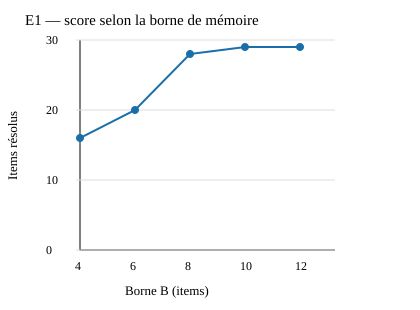

Non-monotonie : False ; plateau observé depuis 10


Verdict E1 : CORROBORE sur les points testés


In [10]:
// Le graphique reprend exactement les scores calculés et garde axes, graduations et légende.
record Graph07(string Svg);
Formatter.Register<Graph07>((g, writer) => writer.Write(g.Svg), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Graph07), "image/svg+xml");
string TraceE1(int[] x, IReadOnlyList<int> y)
{
    var points = string.Join(" ", Enumerable.Range(0, x.Length).Select(i => $"{80 + 55 * i},{250 - 7 * y[i]}"));
    var sb = new StringBuilder();
    sb.Append("<svg xmlns='http://www.w3.org/2000/svg' width='420' height='310' viewBox='0 0 420 310'><rect width='420' height='310' fill='white'/>");
    sb.Append("<text x='25' y='25' font-size='15'>E1 — score selon la borne de mémoire</text><path d='M80 40 V250 H335' stroke='black' fill='none'/>");
    foreach (int tick in new[]
    {
        0,
        10,
        20,
        30
    }

    )
    {
        int py = 250 - 7 * tick;
        sb.Append($"<path d='M76 {py} H335' stroke='#ddd'/><text x='46' y='{py + 4}' font-size='12'>{tick}</text>");
    }

    for (int i = 0; i < x.Length; i++)
        sb.Append($"<text x='{75 + 55 * i}' y='270' font-size='12'>{x[i]}</text>");
    sb.Append($"<polyline points='{points}' fill='none' stroke='#1a6faa' stroke-width='2'/>");
    for (int i = 0; i < x.Length; i++)
        sb.Append($"<circle cx='{80 + 55 * i}' cy='{250 - 7 * y[i]}' r='4' fill='#1a6faa'/>");
    sb.Append("<text x='125' y='295' font-size='13'>Borne B (items)</text><text transform='translate(17 180) rotate(-90)' font-size='13'>Items résolus</text></svg>");
    return sb.ToString();
}

display(new Graph07(TraceE1(bornes, scores)));
// Un plateau observé exige au moins deux points distincts et ne prédit rien hors plage.
int? PlateauObserve(int[] x, IReadOnlyList<int> y)
{
    if (x.Length != y.Count)
        throw new ArgumentException("Tailles de données différentes");
    if (x.Distinct().Count() != x.Length)
        throw new ArgumentException("Les budgets doivent être distincts");
    for (int i = 0; i < x.Length - 1; i++)
        if (Enumerable.Range(i, x.Length - i).All(j => y[j] == y[i]))
            return x[i];
    return null;
}

if (PlateauObserve(new[] { 4 }, new[] { 7 })is not null || PlateauObserve(new[] { 4, 6, 8 }, new[] { 1, 2, 3 })is not null || PlateauObserve(new[] { 4, 6, 8 }, new[] { 1, 2, 2 }) != 6)
    throw new Exception("Garde du plateau incorrecte");
bool doublonsRejetes = false;
try
{
    PlateauObserve(new[] { 4, 4 }, new[] { 7, 7 });
}
catch (ArgumentException)
{
    doublonsRejetes = true;
}

if (!doublonsRejetes)
    throw new Exception("Budgets doublons acceptés");
bool nonmono = Enumerable.Range(0, bornes.Length - 1).Any(i => scores[i + 1] < scores[i]);
int? plateau = PlateauObserve(bornes, scores);
Console.WriteLine($"Non-monotonie : {nonmono} ; plateau observé depuis {(plateau?.ToString() ?? "absent")}");
Console.WriteLine($"Verdict E1 : {(nonmono ? "REFUTE" : plateau is null ? "PLATEAU NON ATTEINT" : "CORROBORE sur les points testés")}");


### Lecture du résultat — la courbe corrobore la prédiction

Le verdict rendu est « CORROBORE » : la courbe score(B) ne présente aucune non-monotonie et plateaute à partir de B = 10. La figure affiche la courbe ; le texte résume le test — réduire la mémoire dégrade bien le solveur, les deux derniers points observés sont égaux. Ce résultat décrit uniquement la plage testée : il ne prouve pas que le score restera constant au-delà, ni la fidélité cognitive du modèle.

## 6. E2 — la discrimination à la borne

**Prédiction falsifiable.** Si la métrique de longueur et le modèle borné décrivent correctement *ce qui tient en mémoire*, alors le seuil de basculement d'une suite géométrique `f(n−1)·k` doit être **exactement** le plus petit B auquel le dernier produit de la chaîne (celui de la prédiction) devient borné — calculé avant la mesure par `Mult`, prédicat également utilisé par le solveur. Une mesure qui bascule avant ou après son seuil prédit réfute l'opérationnalisation.

**Contrôle de l'expérience** : la recherche est figée sur la classe des descriptions directes (longueur ≤ 4 — la forme `f(n−1)·k`, son jumeau par regard arrière `f(n−2)·k²` quand k² ≤ 99, le double `f(n−1)+f(n−1)`), pour isoler l'effet de la **borne** de l'ingéniosité de la recherche complète. Le seuil prédit est le minimum de ces routes, chacune sondée par `Mult`/`Addition` avant le balayage. Les deux parcours partagent ces prédicats : leur accord contrôle la cohérence du modèle, pas sa fidélité au raisonnement humain. En longueur ≤ 5, le solveur trouve en effet des routes alternatives plus économiques — par exemple les doubles `2, 4, 8, 16, 32` se calculent dès B=5 par `8 · (f(n−2) ÷ 2)` : c'est la richesse du langage, mesurée par E1/E3, pas ce que E2 veut tester.

In [11]:
// Confronter seuils estimés et recherche directe, avec les mêmes prédicats de coût.
(BigInteger[] seq, BigInteger attendu) Geometrique(int k, int premier = 2, int compte = 5)
{
    var v = new BigInteger[compte];
    v[0] = premier;
    for (int i = 1; i < compte; i++)
        v[i] = v[i - 1] * k;
    return (v, v.Last() * k);
}

int? Premier(Func<int, bool> f, int max = 15)
{
    for (int B = 3; B <= max; B++)
        if (f(B))
            return B;
    return null;
}

int? SeuilPredit(int k)
{
    var(seq, _) = Geometrique(k);
    // Plusieurs expressions peuvent produire le même prochain terme à des coûts différents.
    var routes = new List<Func<int, bool>>
    {
        B => Mult(seq.Last(), k, B)
    };
    if (k * k <= 99)
        routes.Add(B => Mult(seq[^2], k * k, B));
    if (k == 2)
        routes.Add(B => Addition(seq.Last(), seq.Last(), B));
    var vals = routes.Select(f => Premier(f)).Where(v => v is not null).Select(v => v.Value).ToArray();
    return vals.Length == 0 ? null : vals.Min();
}

bool tous = true;
foreach (int k in new[]
{
    2,
    3,
    7,
    17,
    23
}

)
{
    var(seq, attendu) = Geometrique(k);
    var seuil = SeuilPredit(k);
    int? mesure = Premier(B =>
    {
        var r = Resoudre(seq, B, 4, false, new[] { 0 });
        return r is not null && r.Prediction == attendu;
    });
    bool accord = seuil == mesure;
    tous &= accord;
    Console.WriteLine($"k={k}, attendu={attendu}, seuil={seuil}, bascule={mesure} : {(accord ? "MATCH" : "ÉCART")}");
}

Console.WriteLine("Verdict E2 : " + (tous ? "CORROBORE (cohérence interne)" : "REFUTE"));


k=2, attendu=64, seuil=7, bascule=7 : MATCH


k=3, attendu=486, seuil=7, bascule=7 : MATCH


k=7, attendu=33614, seuil=8, bascule=8 : MATCH


k=17, attendu=2839714, seuil=13, bascule=13 : MATCH


k=23, attendu=12872686, seuil=13, bascule=13 : MATCH


Verdict E2 : CORROBORE (cohérence interne)


### Lecture du résultat — le basculement tombe sur le seuil prédit

Pour les cinq suites géométriques testées, le basculement mesuré du solveur coïncide exactement avec le seuil prédit par `Mult` : k=2 et k=3 basculent à B=7, k=7 à B=8, k=17 et k=23 à B=13 — cinq MATCH sur cinq. Le seuil est calculé avant la mesure mais avec les mêmes prédicats que le solveur : les cinq accords corroborent la cohérence interne des parcours, sans validation indépendante de la fidélité cognitive.

### Exercice 3 — Construire une bascule de budget

Écrire `ItemBascule()` pour renvoyer une suite géométrique de cinq termes commençant par 2 et sa raison entière. Avec une recherche directe jusqu'à la longueur 5, la prédiction doit échouer à $B=8$ et réussir à $B=13$ ; le contrôle exécute les deux recherches. Le stub renvoie `null`.

In [12]:
(BigInteger[] sequence, int raison)? ItemBascule()
{
    // TODO : construire cinq termes géométriques qui échouent à B=8 et réussissent à B=13.
    return null;
}

var itemEx3 = ItemBascule();
if (itemEx3 is null)
    Console.WriteLine("Exercice 3 à compléter");
else
{
    var(v, k) = itemEx3.Value;
    if (v is null || v.Length != 5 || v[0] != 2 || k < 2 || Enumerable.Range(1, 4).Any(i => v[i] != v[i - 1] * k))
        throw new Exception("Suite géométrique invalide");
    var r8 = Resoudre(v, 8, 5, false, new[] { 0 });
    var r13 = Resoudre(v, 13, 5, false, new[] { 0 });
    var attendu = v[^1] * k;
    if (r8 is not null && r8.Prediction == attendu || r13 is null || r13.Prediction != attendu)
        throw new Exception("La suite ne bascule pas entre B=8 et B=13");
    Console.WriteLine($"k={k} : B8={(r8 is null ? "aucun" : r8.Prediction.ToString())}, B13={r13.Prediction}, attendu={attendu}");
}


Exercice 3 à compléter


## 7. E3 — baselines honnêtes

Deux baselines classiques, sur la même batterie :

- **interpolation polynomiale** : le polynôme de degré l−1 passant par les l points, évalué en l (Lagrange, arithmétique exacte par coefficients binomiaux `BigInteger` : $\sum_{j=0}^{l-1}(-1)^{l-1-j}\binom lj a_j$) ;
- **différences finies** : si le tableau des différences devient constant à profondeur d, extrapoler.

L'interpolation polynomiale « résout » tout item par construction — mais avec le **mauvais terme** dès que la séquence n'est pas polynomiale : c'est le contre-exemple vivant de la thèse du papier (le plus court programme n'est pas le plus court *polynôme*). Le verdict se lit par classe.

In [13]:
// L'interpolation aux indices entiers est évaluée exactement par coefficients binomiaux.
BigInteger Interpolation(IReadOnlyList<BigInteger> seq)
{
    int n = seq.Count;
    BigInteger somme = 0, choose = 1;
    for (int j = 0; j < n; j++)
    {
        // Mise à jour entière du coefficient binomial sans factorielle intermédiaire.
        if (j > 0)
            choose = choose * (n - j + 1) / j;
        somme += ((n - 1 - j) % 2 == 0 ? 1 : -1) * choose * seq[j];
    }

    return somme;
}

BigInteger? Differences(IReadOnlyList<BigInteger> seq)
{
    var rows = new List<List<BigInteger>>
    {
        seq.ToList()
    };
    while (rows[^1].Count > 1)
    {
        var last = rows[^1];
        var next = Enumerable.Range(0, last.Count - 1).Select(i => last[i + 1] - last[i]).ToList();
        rows.Add(next);
        if (next.Distinct().Count() == 1)
        {
            // Remonter les dernières différences prolonge chaque ligne d’un terme.
            BigInteger v = next[0];
            for (int i = rows.Count - 2; i >= 0; i--)
                v = rows[i][^1] + v;
            return v;
        }
    }

    return null;
}

var classes = new[]
{
    "arith",
    "geo",
    "recc",
    "mod2",
    "poly",
    "mixte"
};
var e3 = new Dictionary<string, int[]>();
foreach (string cls in classes)
    e3[cls] = new int[3];
foreach (var item in batterie)
{
    var r = Resoudre(item.seq, 8, 5, true, Enumerable.Range(0, 4));
    if (r is not null && r.Prediction == item.attendu)
        e3[item.classe][0]++;
    if (Interpolation(item.seq) == item.attendu)
        e3[item.classe][1]++;
    if (Differences(item.seq) == item.attendu)
        e3[item.classe][2]++;
}

Console.WriteLine("Classe | solveur | interpolation | différences finies");
foreach (string cls in classes)
    Console.WriteLine($"{cls}: {e3[cls][0]}/5, {e3[cls][1]}/5, {e3[cls][2]}/5");
Console.WriteLine($"Totaux : {classes.Sum(c => e3[c][0])}/30, {classes.Sum(c => e3[c][1])}/30, {classes.Sum(c => e3[c][2])}/30");


Classe | solveur | interpolation | différences finies


arith: 5/5, 4/5, 4/5


geo: 5/5, 0/5, 0/5


recc: 5/5, 0/5, 0/5


mod2: 5/5, 0/5, 0/5


poly: 5/5, 5/5, 5/5


mixte: 3/5, 0/5, 0/5


Totaux : 28/30, 9/30, 9/30


### Lecture du résultat — le solveur borné domine, sauf à égalité sur les polynômes

À B=8, le solveur borné atteint 28/30 contre 9/30 pour l'interpolation polynomiale et 9/30 pour les différences finies. Par classe, il fait 5/5 sur arith, geo, recc, mod2 et poly, et 3/5 sur mixte : les deux baselines ne font 5/5 que sur poly et 4/5 sur arith, et 0/5 sur geo, recc, mod2 et mixte. L'interpolation ne « gagne » que là où la réponse est polynomiale — en payant des réponses fausses ailleurs, ce qui est le contre-exemple vivant de la thèse du papier.

## 8. Exercices

Les trois exercices sont placés au fil du parcours : [regard admissible](#exercice-1--regard-admissible), [départage](#exercice-2--départager-deux-candidats) et [bascule de budget](#exercice-3--construire-une-bascule-de-budget). Les stubs restent ouverts.

## 9. Conclusion — verdicts et limites

**Ce qui a été mesuré** (les sorties ci-dessus font foi — les cellules E1/E2/E3 rendent leurs verdicts dans le code, y compris négatifs le cas échéant) :

- **E1** : courbe score(B) sur batterie maison de 30 items — verdict de monotonie/plateau rendu par la cellule dédiée ;
- **E2** : correspondance entre seuils prédits par `bounded_mul` et basculements mesurés du solveur ;
- **E3** : le solveur borné contre l'interpolation polynomiale et les différences finies, par classe d'item.

**Limites, déclarées :**

1. la batterie est maison, pas l'IST — aucun score n'est comparable au 28/38 du papier ;
2. le TRS à tables du papier est **opérationnalisé** (arithmétique décomposée sous budget, gestes élémentaires ×10/+1 à coût réduit), pas réimplémenté littéralement — les prédicats estiment la faisabilité sous budget, sans produire une réécriture arithmétique correcte ni reproduire la bibliothèque de règles exacte ;
3. budget de recherche borné : numérales ≤ 99, regards ≤ 3, longueur ≤ 5 — les termes de longueur 7 (ex. `n·n·n·n`) sont hors budget de la démo, limite de la démonstration et non du langage ;
4. implémentation unique, solveur déterministe — la sensibilité au choix des items n'est pas échantillonnée.

**Référence.** Strannegård, Nizamani, Sjöberg, Engström — *Bounded Kolmogorov Complexity Based on Cognitive Models*, AGI 2013, LNAI 7999 (Springer). PDF archivé dans la bibliographie privée du projet, jamais dans le dépôt public.

## À retenir

1. **La borne combine estimation et contrôle du résultat.** Le produit `67 · 89` tient en 5 symboles, mais le prédicat simplifié le refuse à B=8 : la sortie de la section 3 le mesure — borné à B=8 : `False`, à B=12 : `True`. La longueur d’un terme ne détermine pas à elle seule son acceptation par cet estimateur.
2. **Le solveur décrit, puis prédit juste.** Les sept séquences de démonstration reçoivent toutes un terme et une prédiction corrects — 256 pour `2, 2, 4, 8, 32` par `(f(n-1) . f(n-2))` (L=3), 34 pour la Fibonacci décalée, 11111 pour les repunits — par énumération ; les durées dépendent de la machine.
3. **E1 corrobore la prédiction de monotonie.** Sur la batterie maison de 30 items, le score suit la borne : 16/30 à B=4, 20/30 à B=6, 28/30 à B=8, 29/30 à B=10 — aucune non-monotonie, plateau depuis B=10.
4. **E2 corrobore la discrimination à la borne.** Le seuil de basculement des suites géométriques tombe exactement sur le plus petit B admissible : 7 pour k=2 et k=3, 8 pour k=7, 13 pour k=17 et k=23 — cinq MATCH sur cinq.
5. **Le solveur borné domine les baselines honnêtes.** 28/30 (à B=8) contre 9/30 pour l'interpolation polynomiale et 9/30 pour les différences finies ; l'interpolation ne rejoint le solveur que sur la classe `poly` (5/5) — en répondant partout, juste souvent à côté : un modèle cognitif borné doit aussi savoir ne pas répondre.

## Vérifiez votre compréhension

1. `67 · 89` est refusé à B=8 et accepté à B=12, alors que sa longueur (5) ne change pas. Que vérifient les prédicats et la taille des résultats, et pourquoi cela ne constitue-t-il pas une chaîne de réécriture fidèle ?
2. À B=8, deux items manquent, de deux façons : `(2, 3, 5, 9, 17)` reçoit une réponse fausse (15 au lieu de 33), `(6, 36, 216, 1296)` ne reçoit aucune prédiction. Que révèle la coexistence de ces deux modes d'échec sur ce que le modèle affirme de l'agent borné ?
3. Pour k=7 le seuil mesuré est 8 ; pour k=17 il monte à 13. Pourquoi le seuil issu des prédicats et la recherche du solveur concordent-ils dans ces cinq cas, et quelle limite vient du fait qu’ils partagent les mêmes prédicats ?
4. L'interpolation de Lagrange répond aux 30 items et en réussit 9 ; le solveur borné n'en résout que 28, mais ses deux échecs sont propres (une réponse fausse, une absence de réponse). Pourquoi la seconde ligne est-elle plus informative pour un modèle cognitif que la première ?

## Pour aller plus loin

- **Carnet suivant** : [Complexity-07b — Le tour des grands nombres](Complexity-07b-LeTourDesGrandsNombres-Python.ipynb) — ici la borne limite ce qu'un agent calcule ; là-bas c'est l'écriture elle-même qui ne tient plus dans l'univers : chaque étage de notation écrit plus court ce qu'il rend plus incalculable.
- **Dans la même série** : [Complexity-07c — Le bilan Mathocalypse](Complexity-07c-LeBilanMathocalypse-Python.ipynb) — la synthèse de la série, du point de vue de ce qui reste calculable ; [Complexity-04b — Conjectures en ligne](Complexity-04b-OnlineConjectures-Secretary-KServer-Python.ipynb) — un autre agent borné, qui doit décider sans jamais pouvoir tout revoir.
- **Carnet voisin d'une autre série** : [Planners-12 — LOOP](../../SymbolicAI/Planners/04-NeuroSymbolic/Planners-12-LOOP-Python.ipynb) — l'agent borné qui apprend : là où ce carnet énumère sous une fenêtre de mémoire, LOOP imite des plans optimaux — précision finale 4/4 (100 %) sur son banc mesuré ; son banc de couverture, imitation contre politique aléatoire, est en cours d'intégration à la série.
- **Lecture** : Strannegård, Nizamati, Sjöberg et Engström (2013), *Bounded Kolmogorov Complexity Based on Cognitive Models* — la méthode que ce carnet réimplémente from scratch (langage de termes, métrique de longueur, calcul borné par mémoire de travail) ; copie archivée au gisement partagé : `Bibliographie IA/MachineLearning/Deep Learning Foundations/2013 - Strannegard et al - Bounded Kolmogorov Complexity Based on Cognitive Models.pdf`. Les items du test IST cités par le papier restent sous droits — la batterie de 30 items est de construction maison.